<a href="https://colab.research.google.com/github/quentin-garcia-3b1724235/canadian-banks-portfolio-analysis/blob/main/notebooks/canadian_banks_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Canadian Big Six Banks: Portfolio Performance and Risk Analysis

This notebook analyzes the performance and risk of a portfolio made of Canada’s six largest banks, using daily market data from Yahoo Finance.

##Section 0 : Setup

###0.1 Install and test yfinance

In [59]:
!pip install --upgrade --quiet yfinance

In [60]:
import yfinance as yf
import pandas as pd

print("yfinance version:", yf.__version__)

test = yf.download("RY.TO", period="5d", auto_adjust=False, progress=False)
test

yfinance version: 1.8.0


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,RY.TO,RY.TO,RY.TO,RY.TO,RY.TO,RY.TO
Date,,,,,,
2026-11-02,286.209991,286.209991,287.529999,284.000000,284.459991,2792000
2026-11-03,285.420013,285.420013,287.000000,283.529999,285.350006,2093600
2026-11-04,292.570007,292.570007,293.670013,287.500000,288.829987,2495100
2026-11-05,285.859985,285.859985,295.489990,285.510010,294.890015,3162000
2026-11-06,284.160004,284.160004,287.299988,283.250000,285.600006,2480300


###0.2 Connect Google Drive

In [61]:
from google.colab import drive
drive.mount("/content/drive")

import os
PROJECT_DIR = "/content/drive/MyDrive/canadian-banks-portfolio"
os.makedirs(f"{PROJECT_DIR}/data", exist_ok=True)
print(os.listdir(PROJECT_DIR))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['data']


##1. Data

Download 20 years of daily prices for the six banks and the benchmark, then save them as CSV files.


###1.1 Parameters

In [62]:
TICKERS = {
    "RY.TO": "RBC",
    "TD.TO": "TD",
    "BNS.TO": "Scotiabank",
    "BMO.TO": "BMO",
    "CM.TO": "CIBC",
    "NA.TO": "National Bank",
}
BENCHMARK = {"XIC.TO": "TSX Composite ETF"}

START_DATE = "2006-01-01"
END_DATE = "2026-01-01"

###1.2 Download daily prices

In [63]:
RAW_FILE = f"{PROJECT_DIR}/data/raw_yfinance.csv"
all_tickers = list(TICKERS) + list(BENCHMARK)

if os.path.exists(RAW_FILE):
    raw = pd.read_csv(RAW_FILE, header=[0, 1], index_col=0, parse_dates=True)
    print("Loaded from Google Drive (no download)")
else:
    raw = yf.download(
        all_tickers,
        start=START_DATE,
        end=END_DATE,
        auto_adjust=False,
        actions=True,
        progress=False,
    )
    if raw.empty or raw["Adj Close"].dropna(axis=1, how="all").shape[1] < len(all_tickers):
      raise ValueError("Download incomplete: nothing was saved. Try again later.")
    raw.to_csv(RAW_FILE)
    print("Downloaded from Yahoo Finance and saved to Google Drive")

print(raw.shape)
raw.columns.get_level_values(0).unique()

Loaded from Google Drive (no download)
(5020, 57)


Index(['Adj Close', 'Capital Gains', 'Close', 'Dividends', 'High', 'Low',
       'Open', 'Stock Splits', 'Volume'],
      dtype='object', name='Price')

###1.3 Extract adjusted prices, closing prices and dividends

In [64]:
adj_close = raw["Adj Close"]
close = raw["Close"]
dividends = raw["Dividends"]

adj_close.tail()

Ticker,BMO.TO,BNS.TO,CM.TO,NA.TO,RY.TO,TD.TO,XIC.TO
Date,,,,,,,
2025-12-23,173.018265,97.054573,122.814125,170.928589,228.010574,125.145035,50.292862
2025-12-24,172.989197,97.313927,122.862648,171.532501,227.815720,125.378006,50.234104
2025-12-29,174.356415,97.285103,122.921371,171.885681,229.111420,125.795410,50.067642
2025-12-30,173.328552,97.333138,122.637558,170.374969,228.936035,126.008972,50.029243
2025-12-31,172.843735,97.237091,121.776329,169.325333,227.952118,125.572151,49.773232


###1.4 Check RBC’s recent dividends

In [65]:
try:
    ry_dividends = yf.Ticker("RY.TO").dividends
    print(ry_dividends.tail(6))
except Exception as error:
    print("Could not reach Yahoo Finance, try again later:", error)

Date
2025-07-24 09:30:00-04:00    1.54
2025-10-27 09:30:00-04:00    1.54
2026-01-26 09:30:00-05:00    1.64
2026-04-23 09:30:00-04:00    1.64
2026-07-27 09:30:00-04:00    1.76
2026-10-26 09:30:00-04:00    1.76
Name: Dividends, dtype: float64


###1.5 Effect of dividends on RBC’s growth

In [66]:
ry_close = close["RY.TO"].dropna()
ry_adj = adj_close["RY.TO"].dropna()

price_growth = ry_close.iloc[-1] / ry_close.iloc[0] - 1
total_growth = ry_adj.iloc[-1] / ry_adj.iloc[0] - 1

print(f"RBC price growth (Close):     {price_growth:.0%}")
print(f"RBC total growth (Adj Close): {total_growth:.0%}")

RBC price growth (Close):     410%
RBC total growth (Adj Close): 1006%


Over 2006–2025, RBC’s share price grew by 410%, but its total return with dividends reinvested reached 1,006%. More than half of the total gain therefore came from dividends. This is why all return calculations in this project use adjusted prices: closing prices alone would strongly understate the performance of dividend-paying stocks such as banks. Assumption: dividends are reinvested with no taxes or fees.

###1.6 Save the data to Google Drive

In [67]:
adj_close.to_csv(f"{PROJECT_DIR}/data/adj_close_prices.csv")
close.to_csv(f"{PROJECT_DIR}/data/close_prices.csv")
dividends.to_csv(f"{PROJECT_DIR}/data/dividends.csv")

print(os.listdir(f"{PROJECT_DIR}/data"))

['adj_close_prices.csv', 'close_prices.csv', 'dividends.csv', 'raw_yfinance.csv', 'tbill_3m_yield.csv']


##2. Returns and data quality checks

Compute daily returns from adjusted prices and check that the data is reliable before any analysis.

###2.1 Load the saved data

In [68]:
import numpy as np

prices = pd.read_csv(
    f"{PROJECT_DIR}/data/adj_close_prices.csv",
    index_col=0,
    parse_dates=True,
)
prices = prices[list(TICKERS) + list(BENCHMARK)]

print("Period:", prices.index.min().date(), "to", prices.index.max().date())
print("Trading days:", len(prices))
prices.head()

Period: 2006-01-03 to 2025-12-31
Trading days: 5020


,RY.TO,TD.TO,BNS.TO,BMO.TO,CM.TO,NA.TO,XIC.TO
Date,,,,,,,
2006-01-03,20.603638,14.001645,18.137629,26.424767,14.500978,13.001815,10.410629
2006-01-04,20.794586,14.053527,18.203585,26.627817,14.600212,12.911553,10.456909
2006-01-05,20.666538,14.053527,18.176418,26.667635,14.716300,12.920151,10.448230
2006-01-06,20.531765,13.985863,18.021242,26.516331,14.787442,12.834190,10.591413
2006-01-09,20.421684,14.035487,17.866049,26.337185,14.772465,12.834190,10.555261


###2.2 Check missing values

In [69]:
print("Missing values per ticker:")
print(prices.isna().sum())

rows_with_missing = prices[prices.isna().any(axis=1)]
print("\nDays with at least one missing price:", len(rows_with_missing))
rows_with_missing

Missing values per ticker:
RY.TO     0
TD.TO     0
BNS.TO    0
BMO.TO    0
CM.TO     0
NA.TO     0
XIC.TO    0
dtype: int64

Days with at least one missing price: 0


,RY.TO,TD.TO,BNS.TO,BMO.TO,CM.TO,NA.TO,XIC.TO
Date,,,,,,,


In [70]:
prices_clean = prices.dropna()
print("Days removed:", len(prices) - len(prices_clean))

Days removed: 0


###2.3 Compute simple and log returns

In [71]:
simple_returns = prices_clean.pct_change().dropna()
log_returns = np.log(prices_clean / prices_clean.shift(1)).dropna()

simple_returns.head()

,RY.TO,TD.TO,BNS.TO,BMO.TO,CM.TO,NA.TO,XIC.TO
Date,,,,,,,
2006-01-04,0.009268,0.003705,0.003636,0.007684,0.006843,-0.006942,0.004445
2006-01-05,-0.006158,0.000000,-0.001492,0.001495,0.007951,0.000666,-0.000830
2006-01-06,-0.006521,-0.004815,-0.008537,-0.005674,0.004834,-0.006653,0.013704
2006-01-09,-0.005361,0.003548,-0.008612,-0.006756,-0.001013,0.000000,-0.003413
2006-01-10,0.008580,-0.005786,-0.001520,0.000755,0.004690,0.006363,-0.001782


###2.4 Consistency check with Section 1

In [72]:
total_from_simple = (1 + simple_returns["RY.TO"]).prod() - 1
total_from_log = np.exp(log_returns["RY.TO"].sum()) - 1

print(f"RBC total return from simple returns: {total_from_simple:.0%}")
print(f"RBC total return from log returns:    {total_from_log:.0%}")

(simple_returns - log_returns).abs().max()

RBC total return from simple returns: 1006%
RBC total return from log returns:    1006%


,0
RY.TO,0.010103
TD.TO,0.014306
BNS.TO,0.012762
BMO.TO,0.015153
CM.TO,0.016604
NA.TO,0.016971
XIC.TO,0.007978


###2.5 Look for extreme and zero returns

In [73]:
big_moves = simple_returns[(simple_returns.abs() > 0.10).any(axis=1)]
print("Days with a move larger than 10%:", len(big_moves))
big_moves.round(3)

Days with a move larger than 10%: 16


,RY.TO,TD.TO,BNS.TO,BMO.TO,CM.TO,NA.TO,XIC.TO
Date,,,,,,,
2008-10-14,0.146,0.131,0.113,0.125,0.141,0.054,0.071
2008-11-20,-0.134,-0.127,-0.133,-0.123,-0.124,-0.167,-0.083
2008-11-24,0.069,0.039,0.038,0.053,0.037,0.127,0.035
2008-11-28,0.111,0.096,0.128,0.069,0.120,0.075,0.039
2008-12-19,0.007,0.025,-0.010,0.009,0.020,0.126,0.014
2009-02-24,0.103,0.075,0.084,0.061,0.078,0.058,0.024
2009-02-26,0.064,0.059,0.061,0.119,0.061,0.097,0.028
2009-03-10,0.144,0.110,0.123,0.102,0.107,0.062,0.038
2009-03-23,0.076,0.103,0.079,0.060,0.083,0.102,0.047


In [74]:
simple_returns.loc["2008-12-15":"2008-12-31", ["NA.TO", "XIC.TO"]].round(3)

,NA.TO,XIC.TO
Date,,
2008-12-15,-0.071,-0.004
2008-12-16,-0.021,0.029
2008-12-17,0.001,0.019
2008-12-18,-0.077,-0.054
2008-12-19,0.126,0.014
2008-12-22,0.036,-0.026
2008-12-23,0.010,0.001
2008-12-24,-0.004,-0.004
2008-12-29,0.055,0.042


In [75]:
(simple_returns == 0).sum()

,0
RY.TO,49
TD.TO,38
BNS.TO,51
BMO.TO,31
CM.TO,37
NA.TO,60
XIC.TO,124


In [76]:
(simple_returns["XIC.TO"] == 0).groupby(simple_returns.index.year).sum()

,XIC.TO
Date,
2006,3
2007,0
2008,1
2009,9
2010,12
2011,6
2012,12
2013,10
2014,14


###2.6 Check the benchmark’s capital gains distributions

In [77]:
try:
    xic_capital_gains = yf.Ticker("XIC.TO").capital_gains
    print(xic_capital_gains)
except Exception as error:
    print("Could not reach Yahoo Finance, try again later:", error)

Series([], Name: Capital Gains, dtype: object)


Only 16 trading days show a daily move larger than 10% for at least one ticker, and all of them fall within two crises: the 2008–2009 global financial crisis and the COVID-19 crash of March 2020. Most of these days (11 out of 16) are sharp rebounds rather than falls, which is typical of crisis periods. The most bank-specific swing (National Bank: −7.7% on December 18, 2008, then +12.6% the next day) was checked: press articles confirm the drop and link it to the bank’s exposure to the Canadian asset-backed commercial paper crisis, and the rebound does not reverse afterwards, which is consistent with a real market move rather than a data error. Days with no price change are rare for banks (about 1% of days) and more frequent for XIC (2.5%); they are spread over all years, with no concentration at the start of the period, so there is no sign of stale prices. One limitation: a trading halt on the Toronto Stock Exchange on December 17, 2008 distorts the split of returns between December 17 and 18, although the two-day total is consistent. Conclusion: the data is reliable, and extreme days are real market events, so they are kept, as they matter most for risk measures.

##3. Performance

Measure the return, risk and risk-adjusted return of each bank and of the benchmark over 2006–2025.

###3.1 Growth of $100 invested in January 2006

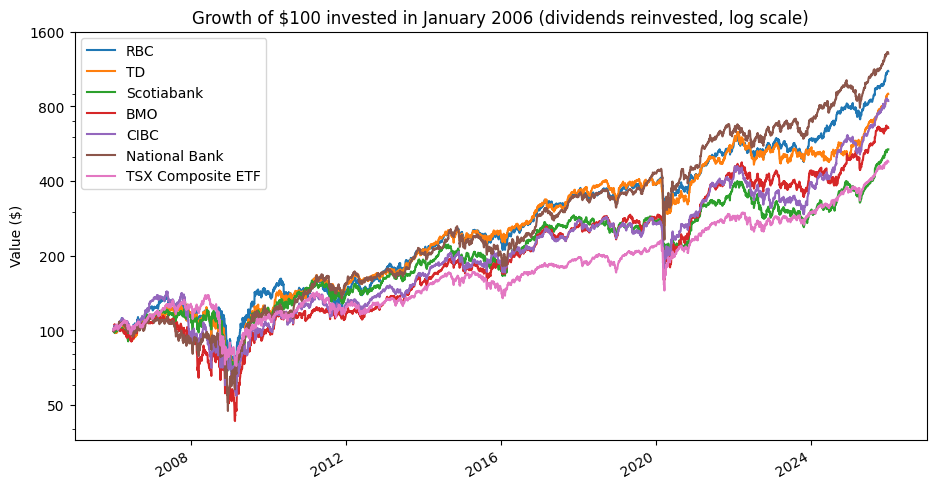

In [78]:
import matplotlib.pyplot as plt
from matplotlib.ticker import NullFormatter, ScalarFormatter

NAMES = {**TICKERS, **BENCHMARK}

growth = 100 * prices_clean / prices_clean.iloc[0]
growth = growth.rename(columns=NAMES)

ax = growth.plot(figsize=(11, 6), logy=True)
ax.set_yticks([50, 100, 200, 400, 800, 1600])
ax.yaxis.set_major_formatter(ScalarFormatter())
ax.yaxis.set_minor_formatter(NullFormatter())
ax.set_title("Growth of $100 invested in January 2006 (dividends reinvested, log scale)")
ax.set_ylabel("Value ($)")
ax.set_xlabel("")
plt.show()

###3.2 Annualized return and volatility

In [79]:
n_years = (prices_clean.index[-1] - prices_clean.index[0]).days / 365.25

total_return = prices_clean.iloc[-1] / prices_clean.iloc[0] - 1
cagr = (1 + total_return) ** (1 / n_years) - 1
volatility = simple_returns.std() * np.sqrt(252)

print(f"Number of years: {n_years:.2f}")

Number of years: 19.99


###3.3 Risk-free rate: 3-month Government of Canada Treasury bills

In [80]:
import requests

SERIES = "TB.CDN.90D.MID"
TBILL_FILE = f"{PROJECT_DIR}/data/tbill_3m_yield.csv"

if os.path.exists(TBILL_FILE):
    tbill = pd.read_csv(TBILL_FILE, index_col=0, parse_dates=True)["tbill_3m_yield"]
    print("Loaded from Google Drive (no download)")
else:
    url = (
        f"https://www.bankofcanada.ca/valet/observations/{SERIES}/json"
        f"?start_date={START_DATE}&end_date={END_DATE}"
    )
    data = requests.get(url, timeout=30).json()
    tbill = pd.Series(
        {
            obs["d"]: float(obs[SERIES]["v"])
            for obs in data["observations"]
            if obs.get(SERIES, {}).get("v")
        },
        name="tbill_3m_yield",
    )
    tbill.index = pd.to_datetime(tbill.index)
    tbill.index.name = "Date"
    tbill.to_csv(TBILL_FILE)
    print("Downloaded from the Bank of Canada and saved to Google Drive")

print(tbill.describe())

Loaded from Google Drive (no download)
count    4995.000000
mean        1.711239
std         1.521567
min         0.000000
25%         0.520000
50%         0.970000
75%         2.650000
max         5.120000
Name: tbill_3m_yield, dtype: float64


###3.4 Sharpe ratio

In [81]:
rf_daily = tbill.reindex(simple_returns.index, method="ffill") / 100 / 252
print("Missing risk-free values:", rf_daily.isna().sum())

excess_returns = simple_returns.sub(rf_daily, axis=0)
sharpe = excess_returns.mean() / excess_returns.std() * np.sqrt(252)
sharpe_se = np.sqrt((1 + sharpe**2 / (2 * 252)) / n_years)

Missing risk-free values: 0


###3.5 Performance summary

In [82]:
summary = pd.DataFrame({
    "Total return": total_return,
    "Annualized return": cagr,
    "Annualized volatility": volatility,
    "Sharpe ratio": sharpe,
    "Sharpe std. error": sharpe_se,
}).rename(index=NAMES)

summary.style.format({
    "Total return": "{:.0%}",
    "Annualized return": "{:.1%}",
    "Annualized volatility": "{:.1%}",
    "Sharpe ratio": "{:.2f}",
    "Sharpe std. error": "{:.2f}",
})

,Total return,Annualized return,Annualized volatility,Sharpe ratio,Sharpe std. error
RBC,1006%,12.8%,21.2%,0.59,0.22
TD,797%,11.6%,21.3%,0.54,0.22
Scotiabank,436%,8.8%,21.4%,0.42,0.22
BMO,554%,9.8%,22.4%,0.46,0.22
CIBC,740%,11.2%,22.7%,0.51,0.22
National Bank,1202%,13.7%,22.7%,0.61,0.22
TSX Composite ETF,378%,8.1%,16.7%,0.45,0.22


###3.6 Calendar-year returns

In [83]:
annual_returns = (1 + simple_returns).groupby(simple_returns.index.year).prod() - 1
annual_returns.rename(columns=NAMES).round(3)

,RBC,TD,Scotiabank,BMO,CIBC,National Bank,TSX Composite ETF
Date,,,,,,,
2006,0.248,0.148,0.151,0.076,0.311,0.124,0.155
2007,-0.056,0.027,-0.001,-0.150,-0.256,-0.172,0.095
2008,-0.257,-0.352,-0.317,-0.413,-0.231,-0.367,-0.334
2009,0.637,0.592,0.571,0.909,0.416,1.014,0.345
2010,-0.039,0.165,0.204,0.078,0.203,0.183,0.174
2011,0.033,0.062,-0.075,0.018,-0.013,0.094,-0.088
2012,0.201,0.138,0.177,0.143,0.137,0.116,0.070
2013,0.240,0.241,0.193,0.216,0.189,0.195,0.124
2014,0.166,0.148,0.037,0.208,0.146,0.165,0.109


###3.7 Robustness check: two sub-periods

In [84]:
for start, end in [("2006", "2015"), ("2016", "2025")]:
    period_returns = simple_returns.loc[start:end]
    years = len(period_returns) / 252
    period_cagr = (1 + period_returns).prod() ** (1 / years) - 1
    print(f"Annualized return, {start}-{end}:")
    print(period_cagr.rename(NAMES).sort_values(ascending=False).round(3), "\n")

Annualized return, 2006-2015:
TD                   0.095
RBC                  0.091
National Bank        0.074
BMO                  0.065
CIBC                 0.065
Scotiabank           0.060
TSX Composite ETF    0.040
dtype: float64 

Annualized return, 2016-2025:
National Bank        0.205
RBC                  0.167
CIBC                 0.163
TD                   0.138
BMO                  0.134
TSX Composite ETF    0.125
Scotiabank           0.117
dtype: float64 



###3.8 Interpretation

Over 2006–2025, every bank delivered a higher annualized return than the TSX Composite ETF (XIC), from 8.8% per year for Scotiabank to 13.7% for National Bank, versus 8.1% for XIC. However, the banks were also riskier: their annualized volatility ranged from 21% to 23%, versus 17% for XIC, because a single bank is far less diversified than an index of hundreds of companies across all sectors. Once risk is taken into account, the picture is much less clear: Sharpe ratios range from 0.42 (Scotiabank) to 0.61 (National Bank), versus 0.45 for XIC. These gaps are small compared with the uncertainty of each estimate (a standard error of about 0.22). The ranking is also unstable over time: TD had the best return in 2006–2015 but only the fourth best in 2016–2025, while National Bank moved from third to first. Conclusion: the banks’ higher returns came with higher risk, and the data does not show that any bank did better than the market once risk is taken into account. A formal comparison of Sharpe ratios, which accounts for the correlation between assets, is carried out in Section 4.

##4.